# Retail Customer Sales — Exploratory Data Analysis (EDA)

**Project:** Data Analyst Training Program — Mini Project 1  
**Dataset:** `retail_customer_sales_dataset.csv` (simulated retail data)  
**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn

## Purpose
This notebook audits, cleans, profiles, and summarizes the supplied retail dataset before it is used for dashboards or further statistical work. It follows the project brief and keeps unusual values visible for human review rather than automatically deleting them.

> **Important:** The dataset is simulated. Do not describe these results as findings from a real company. Review the decision notes and add your own comments before submission.

### How to run
- In Google Colab, upload `retail_customer_sales_dataset.csv` when prompted.
- Run cells from top to bottom.
- Review the printed audit and outlier samples. Confirm whether each cleaning decision is appropriate for the project context.
- The final cell exports `Retail_Customer_Sales_Cleaned.csv`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the CSV: Colab upload first; otherwise use a local file beside this notebook.
try:
    from google.colab import files
    uploaded = files.upload()
    csv_file = next(iter(uploaded))
except Exception:
    csv_file = "retail_customer_sales_dataset.csv"

df = pd.read_csv(csv_file)
print("Dataset shape:", df.shape)
display(df.head())
display(df.tail())
display(df.dtypes.to_frame("data_type"))


Saving retail_customer_sales_dataset.csv to retail_customer_sales_dataset.csv
Dataset shape: (7055, 24)


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN200000,CUST10836,07/03/2023,05/03/2023,-4.0,Femle,72526.29,north,Delhi,Rohini,...,795.11,1.20,405.51,315.63,89.88,UPI,Same-Day,NaN,Medium,Yes
1,TXN200001,CUST10540,2023-04-04,2023-04-13,48.0,Male,73625.14,North,Delhi,New Delhi,...,4560.48,0.41,8072.05,5513.41,2558.64,Credit Card,Same-Day,2.0,High,No
2,TXN200002,CUST10909,2024-10-10,NaN,48.0,Female,46699.89,South,Andhra Pradesh,Visakhapatnam,...,5414.71,0.49,2761.50,2258.73,502.77,Debit Card,Standard,4.0,Low,No
3,TXN200003,CUST10493,23/05/2023,2023-05-27,42.0,Female,60232.01,North,Delhi,Rohini,...,10293.28,0.37,19454.30,16346.53,3107.77,Debit Card,Standard,2.0,High,No
4,TXN200004,CUST10570,2023-02-25,03-02-2023,51.0,Female,45084.11,North,Haryana,Gurugram,...,1704.33,0.33,5709.51,3889.01,1820.50,Credit Card,Same-Day,4.0,Low,Yes


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
7050,TXN201468,CUST10273,2023-11-02,11-10-2023,30.0,Male,48233.21,East,Odisha,Bhubaneswar,...,2901.59,0.40,1740.95,1026.97,713.98,Credit Card,Standard,NaN,High,Yes
7051,TXN203600,CUST11045,18/12/2024,12-19-2024,22.0,Female,29187.07,East,Odisha,Bhubaneswar,...,5848.76,0.04,33688.86,21110.72,12578.14,Cash on Delivery,Same-Day,1.0,Low,Yes
7052,TXN200814,CUST10974,2024-12-21,2024-12-28,21.0,Female,107929.09,West,Gujarat,Surat,...,10049.08,0.37,18992.76,14717.86,4274.90,Net Banking,Standard,5.0,Medium,No
7053,TXN204148,CUST10647,2023-12-17,12-27-2023,31.0,Female,63297.49,South,Andhra Pradesh,Vijayawada,...,1529.03,0.37,3853.16,2219.28,1633.88,Cash on Delivery,Standard,NaN,Low,No
7054,TXN204222,CUST10079,2023-05-25,2023-05-27,26.0,Female,72109.06,South,Karnataka,Mysuru,...,1483.04,0.48,3084.72,1843.60,1241.12,Net Banking,Express,2.0,Low,Yes


,data_type
Transaction_ID,object
Customer_ID,object
Order_Date,object
Delivery_Date,object
Age,float64
Gender,object
Income,float64
Region,object
State,object
City,object


## 1. First look and data-quality audit

The source brief describes approximately 7,000 transaction records and 24 columns. Confirm the actual values below rather than relying on the approximate description.

In [2]:
print("Rows, columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

audit = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "data_type": df.dtypes.astype(str)
}).sort_values("missing_count", ascending=False)
display(audit)
print("Exact duplicate rows:", df.duplicated().sum())

for col in ["Gender", "Region"]:
    print(f"\\n{col} values including missing:")
    display(df[col].value_counts(dropna=False))


Rows, columns: (7055, 24)
\nColumn names:
['Transaction_ID', 'Customer_ID', 'Order_Date', 'Delivery_Date', 'Age', 'Gender', 'Income', 'Region', 'State', 'City', 'Customer_Segment', 'Product_Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit', 'Payment_Method', 'Delivery_Mode', 'Customer_Rating', 'Satisfaction_Level', 'Returned']


,missing_count,missing_percent,data_type
Customer_Rating,1362,19.31,float64
Delivery_Date,175,2.48,object
Satisfaction_Level,105,1.49,object
Age,85,1.20,float64
Income,70,0.99,float64
City,28,0.40,object
Order_Date,0,0.00,object
Transaction_ID,0,0.00,object
Region,0,0.00,object
Gender,0,0.00,object


Exact duplicate rows: 55
\nGender values including missing:


,count
Gender,
Female,3531
Male,3506
Femle,7
male,6
FEMALE,5


\nRegion values including missing:


,count
Region,
North,1809
West,1790
East,1729
South,1713
South,5
north,4
Wst,4
NORTH,1


### Human review checkpoint — audit
- Check the missing-value table and record which fields are genuinely optional.
- Inspect spelling/case variants before standardizing them.
- Exact duplicate rows can be removed, but do not delete rows only because a customer or transaction identifier repeats unless the source rules support that decision.


In [3]:
# Numerical range checks. These are flags, not automatic proof of errors.
checks = {
    "Age_nonpositive_or_over_100": (pd.to_numeric(df["Age"], errors="coerce") <= 0) | (pd.to_numeric(df["Age"], errors="coerce") > 100),
    "Discount_outside_0_to_0.5": (pd.to_numeric(df["Discount"], errors="coerce") < 0) | (pd.to_numeric(df["Discount"], errors="coerce") > 0.5),
    "Income_nonpositive": pd.to_numeric(df["Income"], errors="coerce") <= 0,
    "Quantity_nonpositive": pd.to_numeric(df["Quantity"], errors="coerce") <= 0,
    "Unit_Price_nonpositive": pd.to_numeric(df["Unit_Price"], errors="coerce") <= 0
}
print({name: int(mask.fillna(False).sum()) for name, mask in checks.items()})

# Parse dates; mixed formats are expected according to the data dictionary.
for col in ["Order_Date", "Delivery_Date"]:
    parsed = pd.to_datetime(df[col], errors="coerce", format="mixed")
    print(col, "unparsed non-missing values:", int((df[col].notna() & parsed.isna()).sum()))

order_dt = pd.to_datetime(df["Order_Date"], errors="coerce", format="mixed")
delivery_dt = pd.to_datetime(df["Delivery_Date"], errors="coerce", format="mixed")
print("Delivery before order:", int((delivery_dt.notna() & order_dt.notna() & (delivery_dt < order_dt)).sum()))


{'Age_nonpositive_or_over_100': 10, 'Discount_outside_0_to_0.5': 8, 'Income_nonpositive': 3, 'Quantity_nonpositive': 0, 'Unit_Price_nonpositive': 0}
Order_Date unparsed non-missing values: 0
Delivery_Date unparsed non-missing values: 0
Delivery before order: 451


## 2. Cleaning decisions and rationale

The rules below are a defensible starting point, not a substitute for judgement. Keep a short decision log in your own words after checking the audit output.

| Field / issue | Treatment | Reason |
|---|---|---|
| Exact duplicate rows | Remove exact row duplicates | Repeated identical records can inflate counts and totals |
| Gender / Region | Standardize known case and spelling variants only | The data dictionary gives the canonical categories; unknown values remain visible |
| Order_Date / Delivery_Date | Parse to datetime; unparseable dates become missing | Enables date calculations without guessing |
| Delivery before order | Set the invalid delivery date to missing | Do not swap dates; source brief calls these data errors |
| Age | Values <=0 or >100 flagged as invalid; median imputation after review | These are implausible ages for this customer dataset; median is less sensitive to skew |
| Discount | Values outside 0–0.5 flagged; median imputation after review | The data dictionary defines discount as a proportion in this range |
| Income | Nonpositive values flagged; missing values median-imputed | Income is right-skewed; median is more robust than mean |
| Customer_Rating | Keep missing | The brief says not every order is rated; a missing rating is not necessarily an error |
| Satisfaction_Level | Label missing as `Not Recorded` | Preserves the fact that no response was recorded rather than inventing a rating |
| Other missing fields | Inspect the audit table; document any additional field-specific treatment | Avoid applying one blanket rule to every column |

**Before final submission:** confirm that these choices match the observed records and add your own explanation for any change.

In [4]:
clean = df.drop_duplicates().copy()

# Trim surrounding whitespace from text columns.
for col in clean.select_dtypes(include="object").columns:
    clean[col] = clean[col].map(lambda x: x.strip() if isinstance(x, str) else x)

# Standardize only known Gender variants.
gender_map = {"male": "Male", "m": "Male", "female": "Female", "f": "Female"}
clean["Gender"] = clean["Gender"].map(
    lambda x: gender_map.get(str(x).lower(), x) if pd.notna(x) else x
)

# Standardize known Region variants; unexpected values are retained for review.
region_map = {"north": "North", "nort": "North", "south": "South", "sth": "South",
              "east": "East", "west": "West"}
clean["Region"] = clean["Region"].map(
    lambda x: region_map.get(str(x).lower(), x) if pd.notna(x) else x
)

# Parse dates with mixed input formats.
for col in ["Order_Date", "Delivery_Date"]:
    clean[col] = pd.to_datetime(clean[col], errors="coerce", format="mixed")

# Apply documented validity checks.
clean["Age"] = pd.to_numeric(clean["Age"], errors="coerce")
clean.loc[(clean["Age"] <= 0) | (clean["Age"] > 100), "Age"] = np.nan

clean["Income"] = pd.to_numeric(clean["Income"], errors="coerce")
clean.loc[clean["Income"] <= 0, "Income"] = np.nan

clean["Discount"] = pd.to_numeric(clean["Discount"], errors="coerce")
clean.loc[(clean["Discount"] < 0) | (clean["Discount"] > 0.5), "Discount"] = np.nan

# Median imputation for numeric fields selected above.
for col in ["Age", "Income", "Discount"]:
    clean[col] = clean[col].fillna(clean[col].median())

# Missing satisfaction is explicitly marked; missing ratings remain missing.
clean["Satisfaction_Level"] = clean["Satisfaction_Level"].fillna("Not Recorded")

# Do not silently swap invalid date pairs.
invalid_delivery = (clean["Delivery_Date"].notna() & clean["Order_Date"].notna()
                    & (clean["Delivery_Date"] < clean["Order_Date"]))
clean.loc[invalid_delivery, "Delivery_Date"] = pd.NaT

print("Original rows:", len(df), "| Cleaned rows:", len(clean))
print("Remaining missing values:")
display(clean.isna().sum().to_frame("missing_count"))
print("Gender after standardization:", clean["Gender"].value_counts(dropna=False).to_dict())
print("Region after standardization:", clean["Region"].value_counts(dropna=False).to_dict())


Original rows: 7055 | Cleaned rows: 7000
Remaining missing values:


,missing_count
Transaction_ID,0
Customer_ID,0
Order_Date,0
Delivery_Date,624
Age,0
Gender,0
Income,0
Region,0
State,0
City,28


Gender after standardization: {'Female': 3507, 'Male': 3486, 'Femle': 7}
Region after standardization: {'North': 1799, 'West': 1779, 'East': 1712, 'South': 1706, 'Wst': 4}


## 3. Descriptive statistics

The brief requests mean, median, mode, standard deviation, variance, quartiles, IQR, and percentiles for Age, Income, Quantity, Unit_Price, Discount, Sales, Cost, and Profit.

In [5]:
numeric_cols = ["Age", "Income", "Quantity", "Unit_Price", "Discount", "Sales", "Cost", "Profit"]
stats = clean[numeric_cols].describe(percentiles=[.10, .25, .50, .75, .90]).T
stats["mode"] = clean[numeric_cols].mode().iloc[0]
stats["variance"] = clean[numeric_cols].var()
stats["IQR"] = clean[numeric_cols].quantile(.75) - clean[numeric_cols].quantile(.25)
stats["skewness"] = clean[numeric_cols].skew()
display(stats.round(2))


,count,mean,std,min,10%,25%,50%,75%,90%,max,mode,variance,IQR,skewness
Age,7000.0,37.74,11.45,18.00,22.00,30.00,37.00,45.00,53.00,75.00,18.00,1.311100e+02,15.00,0.28
Income,7000.0,57602.16,73243.56,4293.87,23310.97,33182.93,47953.96,69349.14,97707.57,2500000.00,47953.96,5.364619e+09,36166.21,26.65
Quantity,7000.0,3.49,1.71,1.00,1.00,2.00,3.00,5.00,6.00,6.00,2.00,2.920000e+00,3.00,0.02
Unit_Price,7000.0,4412.18,3042.99,150.35,958.41,2119.73,4003.34,5948.41,7744.96,14987.99,293.48,9.259792e+06,3828.68,1.16
Discount,7000.0,0.25,0.15,0.00,0.05,0.13,0.25,0.38,0.45,0.50,0.25,2.000000e-02,0.25,-0.02
Sales,7000.0,11629.65,13094.74,-100.00,1739.21,3638.46,8167.80,15904.50,25198.26,500000.00,-100.00,1.714722e+08,12266.04,10.30
Cost,7000.0,8027.26,7773.15,54.63,1190.69,2519.21,5724.84,11019.66,17612.41,67482.80,500.23,6.042189e+07,8500.46,2.08
Profit,7000.0,3472.28,3635.59,18.76,468.18,1023.60,2325.04,4643.56,7801.87,33776.53,362.03,1.321749e+07,3619.95,2.40


## 4. Univariate analysis

Use both plots and summary statistics. Skewness describes asymmetry; it does not by itself explain why a customer behaved a certain way.

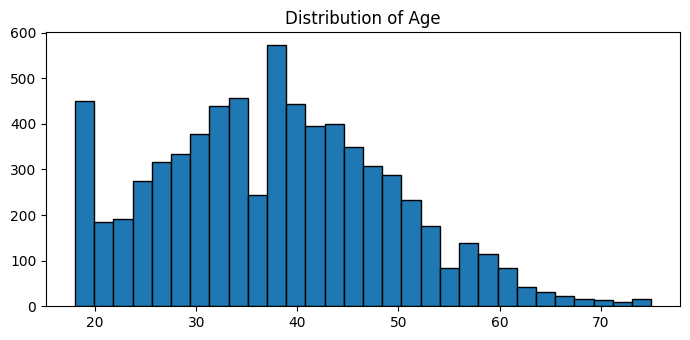

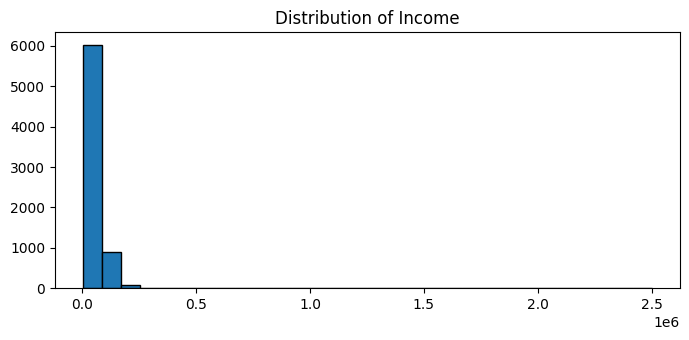

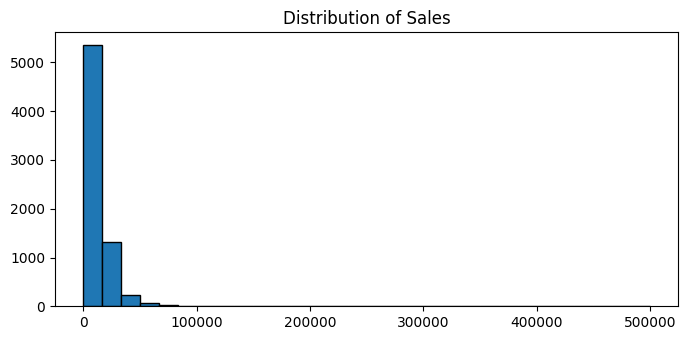

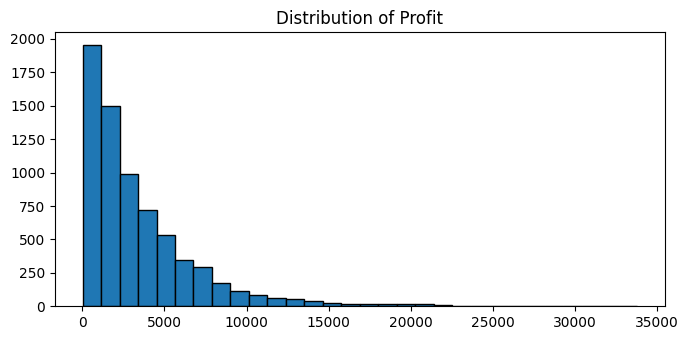

Frequency and proportion — Region


,count,proportion_percent
Region,,
North,1799,25.70
West,1779,25.41
East,1712,24.46
South,1706,24.37
Wst,4,0.06


Frequency and proportion — Product_Category


,count,proportion_percent
Product_Category,,
Clothing,1429,20.41
Grocery,1416,20.23
Electronics,1402,20.03
Furniture,1379,19.70
Office Supplies,1374,19.63


Frequency and proportion — Customer_Segment


,count,proportion_percent
Customer_Segment,,
Corporate,2371,33.87
Consumer,2345,33.50
Home Office,2249,32.13
CORPORATE,13,0.19
consumer,12,0.17
Homeoffice,10,0.14


In [6]:
numeric_plot_cols = ["Age", "Income", "Sales", "Profit"]
for col in numeric_plot_cols:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(clean[col].dropna(), bins=30, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

for col in ["Region", "Product_Category", "Customer_Segment"]:
    freq = clean[col].value_counts(dropna=False).to_frame("count")
    freq["proportion_percent"] = (freq["count"] / len(clean) * 100).round(2)
    print(f"Frequency and proportion — {col}")
    display(freq)


## 5. Outlier detection — IQR method

An IQR flag is a prompt to investigate, not a reason to delete a record. A high-income customer or a large order may be genuine. Review the surrounding transaction context and, where possible, compare with the source record.

In [7]:
outlier_rows = []
for col in ["Sales", "Profit", "Age", "Income"]:
    q1 = clean[col].quantile(.25)
    q3 = clean[col].quantile(.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (clean[col] < lower) | (clean[col] > upper)
    outlier_rows.append({"variable": col, "lower_fence": lower, "upper_fence": upper,
                         "flagged_count": int(mask.sum()),
                         "flagged_percent": mask.mean() * 100})
    print(f"\\nContext sample for {col} outliers:")
    display(clean.loc[mask, ["Transaction_ID", "Customer_ID", "Product_Category",
                             "Region", col]].head(10))
display(pd.DataFrame(outlier_rows).round(2))


\nContext sample for Sales outliers:


,Transaction_ID,Customer_ID,Product_Category,Region,Sales
7,TXN200007,CUST10108,Electronics,East,39134.78
19,TXN200019,CUST10552,Electronics,West,40773.26
20,TXN200020,CUST10307,Grocery,South,36221.69
54,TXN200054,CUST10189,Electronics,East,43010.01
62,TXN200062,CUST10907,Electronics,East,47852.64
63,TXN200063,CUST10667,Electronics,West,37830.57
100,TXN200100,CUST10880,Electronics,East,64121.53
109,TXN200109,CUST10485,Electronics,North,41856.57
126,TXN200126,CUST10587,Electronics,West,39583.57
203,TXN200203,CUST10475,Office Supplies,South,38553.25


\nContext sample for Profit outliers:


,Transaction_ID,Customer_ID,Product_Category,Region,Profit
7,TXN200007,CUST10108,Electronics,East,11111.39
20,TXN200020,CUST10307,Grocery,South,15811.74
62,TXN200062,CUST10907,Electronics,East,18532.50
63,TXN200063,CUST10667,Electronics,West,15416.76
95,TXN200095,CUST10687,Furniture,West,12200.54
100,TXN200100,CUST10880,Electronics,East,18909.06
109,TXN200109,CUST10485,Electronics,North,16238.51
110,TXN200110,CUST10073,Grocery,West,10585.59
126,TXN200126,CUST10587,Electronics,West,14912.65
187,TXN200187,CUST10270,Office Supplies,West,10336.32


\nContext sample for Age outliers:


,Transaction_ID,Customer_ID,Product_Category,Region,Age
30,TXN200030,CUST10713,Electronics,West,72.0
33,TXN200033,CUST10008,Clothing,West,71.0
258,TXN200258,CUST10216,Office Supplies,West,70.0
450,TXN200450,CUST10657,Grocery,North,72.0
558,TXN200558,CUST10706,Clothing,West,70.0
633,TXN200633,CUST10780,Grocery,South,75.0
703,TXN200703,CUST10356,Grocery,West,68.0
715,TXN200715,CUST10271,Grocery,West,70.0
758,TXN200758,CUST10293,Electronics,South,75.0
759,TXN200759,CUST10270,Office Supplies,North,68.0


\nContext sample for Income outliers:


,Transaction_ID,Customer_ID,Product_Category,Region,Income
27,TXN200027,CUST10518,Furniture,North,191677.01
33,TXN200033,CUST10008,Clothing,West,151781.74
55,TXN200055,CUST10160,Office Supplies,South,150436.38
58,TXN200058,CUST10153,Electronics,East,200321.10
67,TXN200067,CUST10144,Office Supplies,East,147008.64
79,TXN200079,CUST10161,Furniture,North,132622.24
102,TXN200102,CUST10452,Grocery,North,136863.51
112,TXN200112,CUST10433,Office Supplies,North,135151.61
141,TXN200141,CUST11117,Clothing,East,185449.81
146,TXN200146,CUST10317,Grocery,West,168359.08


,variable,lower_fence,upper_fence,flagged_count,flagged_percent
0,Sales,-14760.59,34303.55,307,4.39
1,Profit,-4406.33,10073.49,386,5.51
2,Age,7.50,67.50,53,0.76
3,Income,-21066.38,123598.46,327,4.67


### Human review checkpoint — outliers
For each variable, write a short note:
1. What makes the value unusual under the IQR rule?
2. Does the record violate a business rule, or is it merely extreme?
3. What additional evidence would help verify it?
4. Should it be retained, corrected from a source record, or excluded from a specific analysis?

Do not claim that an outlier is an error solely because it is far from the median.

## 6. Feature engineering

Three required calculated fields are created below:
- `Profit_Margin_Percent`: profit as a percentage of sales.
- `Delivery_Days`: elapsed calendar days between order and delivery.
- `Customer_Lifetime_Revenue`: total observed sales for that customer across the rows in this dataset. This value repeats on each transaction belonging to the same customer; it is not revenue from a single order.

A sales reconciliation helper compares recorded sales with the formula in the data dictionary. Small differences may be due to rounding or source calculations.

In [8]:
clean["Profit_Margin_Percent"] = np.where(
    clean["Sales"] != 0, clean["Profit"] / clean["Sales"] * 100, np.nan
)
clean["Delivery_Days"] = (clean["Delivery_Date"] - clean["Order_Date"]).dt.days
clean["Customer_Lifetime_Revenue"] = clean.groupby("Customer_ID")["Sales"].transform("sum")

clean["Calculated_Sales"] = clean["Quantity"] * clean["Unit_Price"] * (1 - clean["Discount"])
clean["Sales_Reconciliation_Difference"] = clean["Sales"] - clean["Calculated_Sales"]
display(clean[["Transaction_ID", "Profit_Margin_Percent", "Delivery_Days",
               "Customer_Lifetime_Revenue", "Sales_Reconciliation_Difference"]].head())
print("Median absolute sales reconciliation difference:",
      clean["Sales_Reconciliation_Difference"].abs().median())


,Transaction_ID,Profit_Margin_Percent,Delivery_Days,Customer_Lifetime_Revenue,Sales_Reconciliation_Difference
0,TXN200000,22.164682,NaN,17542.54,-190.8225
1,TXN200001,31.697524,9.0,55888.48,0.0004
2,TXN200002,18.206410,NaN,132881.18,-0.0021
3,TXN200003,15.974720,4.0,81119.79,0.0008
4,TXN200004,31.885398,5.0,88228.06,0.0045


Median absolute sales reconciliation difference: 0.0024000000003070454


## 7. Business questions using groupby

The tables below answer more than five questions. After each table, add a short interpretation and a practical implication. Distinguish a descriptive pattern from a cause.

In [9]:
# Q1. Which region contributes the highest total sales and what is its average order value?
region_summary = clean.groupby("Region").agg(
    Transactions=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Average_Order_Value=("Sales", "mean"),
    Total_Profit=("Profit", "sum")
).sort_values("Total_Sales", ascending=False)
display(region_summary.round(2))

# Q2. Which product category has the lowest average profit margin?
category_summary = clean.groupby("Product_Category").agg(
    Transactions=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit_Margin=("Profit_Margin_Percent", "mean")
).sort_values("Average_Profit_Margin")
display(category_summary.round(2))

# Q3. Which customer segment contributes the most sales?
segment_summary = clean.groupby("Customer_Segment").agg(
    Transactions=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Average_Order_Value=("Sales", "mean"),
    Total_Profit=("Profit", "sum")
).sort_values("Total_Sales", ascending=False)
display(segment_summary.round(2))

# Q4. How do payment methods compare by transaction count and sales?
payment_summary = clean.groupby("Payment_Method").agg(
    Transactions=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Average_Order_Value=("Sales", "mean")
).sort_values("Total_Sales", ascending=False)
display(payment_summary.round(2))

# Q5. How do returned and non-returned orders compare?
return_summary = clean.groupby("Returned").agg(
    Transactions=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)
display(return_summary.round(2))

# Q6. What is the average delivery time by delivery mode?
delivery_summary = clean.groupby("Delivery_Mode").agg(
    Transactions=("Transaction_ID", "count"),
    Average_Delivery_Days=("Delivery_Days", "mean"),
    Total_Sales=("Sales", "sum")
)
display(delivery_summary.round(2))

# Q7. Which states contribute the highest sales?
state_summary = clean.groupby("State").agg(
    Transactions=("Transaction_ID", "count"),
    Total_Sales=("Sales", "sum")
).sort_values("Total_Sales", ascending=False)
display(state_summary.head(10).round(2))


,Transactions,Total_Sales,Average_Order_Value,Total_Profit
Region,,,,
West,1779,21147377.07,11887.23,6290417.77
East,1712,20662267.73,12069.08,6000414.63
North,1799,20532243.74,11413.14,6243127.73
South,1706,19011401.36,11143.85,5759857.87
Wst,4,54236.24,13559.06,12173.60


,Transactions,Total_Sales,Total_Profit,Average_Profit_Margin
Product_Category,,,,
Electronics,1402,27825201.96,8515818.76,20.05
Furniture,1379,13009621.19,3881614.66,28.48
Grocery,1416,13478467.60,4019298.98,29.03
Clothing,1429,13514996.55,3991989.39,29.81
Office Supplies,1374,13579238.84,3897269.81,30.13


,Transactions,Total_Sales,Average_Order_Value,Total_Profit
Customer_Segment,,,,
Consumer,2345,28190060.57,12021.35,8325988.66
Corporate,2371,26919338.94,11353.58,8188343.44
Home Office,2249,25946706.31,11537.00,7682838.69
CORPORATE,13,198930.67,15302.36,60433.13
consumer,12,83571.70,6964.31,25182.70
Homeoffice,10,68917.95,6891.80,23204.98


,Transactions,Total_Sales,Average_Order_Value
Payment_Method,,,
Net Banking,1394,17252161.58,12376.01
Debit Card,1432,16104384.70,11246.08
Cash on Delivery,1405,16089673.60,11451.72
Credit Card,1390,15971370.96,11490.19
UPI,1349,15651343.91,11602.18
Credit card,12,172202.31,14350.19
upi,14,140363.87,10025.99
Netbanking,4,26025.21,6506.30


,Transactions,Total_Sales,Total_Profit
Returned,,,
No,3529,40193910.80,12102972.39
Yes,3471,41213615.34,12203019.21


,Transactions,Average_Delivery_Days,Total_Sales
Delivery_Mode,,,
EXPRESS,13,4.62,132422.55
Express,2370,15.15,26750341.86
Same-Day,2203,13.95,26059914.74
Standard,2402,12.93,28312710.98
standard,12,5.18,152136.01


,Transactions,Total_Sales
State,,
Gujarat,446,5773869.08
Uttar Pradesh,461,5613757.94
Jharkhand,444,5401483.28
West Bengal,437,5396230.06
Maharashtra,464,5395019.32
Rajasthan,438,5347651.10
Punjab,431,5341037.53
Bihar,395,5175249.00
Karnataka,445,5066541.38


### Human interpretation template — complete in your own words
For each question, record:
- **Observation:** quote the actual row/value from the output.
- **Interpretation:** explain what the pattern means in ordinary business language.
- **Possible action:** suggest a reasonable next step.
- **Limitation:** mention one thing the table cannot prove.

Example structure (do not copy without checking your output): “The region with the largest total sales may deserve closer stock planning. However, total sales alone does not show whether it also has the highest profit margin or the most customers.”

## 8. Findings and final review

Use the outputs above to write 5–7 findings. Avoid unsupported statements such as “customers prefer” unless the data directly measures preference. The dataset is simulated, so present all conclusions as patterns in this supplied dataset.

### Before submission
- [ ] Recheck every cleaning decision against the audit output.
- [ ] Explain the treatment for every column with missing values.
- [ ] Review outlier samples; do not automatically delete them.
- [ ] Add your own plain-language interpretations and business implications.
- [ ] Check that every chart has a title and readable labels.
- [ ] Confirm the cleaned CSV opens correctly.
- [ ] Save this notebook with outputs after running all cells.


In [10]:
# Export the cleaned dataset
output_file = "Retail_Customer_Sales_Cleaned.csv"
clean.to_csv(output_file, index=False, date_format="%Y-%m-%d")
print("Saved:", output_file)
try:
    from google.colab import files
    files.download(output_file)
except Exception:
    print("File is saved in the current working directory.")


Saved: Retail_Customer_Sales_Cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>